# Product Recommendation Model: data merge and base Logistic Regression

**Goal:** predict the `product_category` a customer is likely to buy when they visit our social media sites.

**This notebook covers:**
1. Upload and inspect the two CSVs
2. Clean and merge them into one modelling table (one row per transaction)
3. A customer-aware train/test split
4. Model experiments

**Files needed (upload when prompted):** `customer_social_profiles.csv` and `customer_transactions.csv`

In [1]:
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from google.colab import files

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, log_loss,
    classification_report, ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")

CONFIG = {
    "random_state": 42,
    "split": {"test_size": 0.25, "n_splits": 1, "random_state": 42},
    "cv": {"n_splits": 5, "shuffle": True, "random_state": 42},
    "logreg": {
        "C": 1.0,
        "solver": "lbfgs",
        "max_iter": 1000,
        "class_weight": None,
        "random_state": 42,
    },
    "scaler": {"with_mean": True, "with_std": True},
    "dummy": {"strategy": "prior"},
}
CONFIG

{'random_state': 42,
 'split': {'test_size': 0.25, 'n_splits': 1, 'random_state': 42},
 'cv': {'n_splits': 5, 'shuffle': True, 'random_state': 42},
 'logreg': {'C': 1.0,
  'solver': 'lbfgs',
  'max_iter': 1000,
  'class_weight': None,
  'random_state': 42},
 'scaler': {'with_mean': True, 'with_std': True},
 'dummy': {'strategy': 'prior'}}

## Upload the data

Run the next cell and select **both** CSV files (`customer_social_profiles.csv` and `customer_transactions.csv`).

In [2]:
uploaded = files.upload()

def find_file(keyword):
    """Return the uploaded file whose name contains the keyword (tolerates names like 'file (1).csv')."""
    matches = [name for name in uploaded if keyword in name.lower()]
    if len(matches) != 1:
        raise ValueError(f"Expected exactly one uploaded file containing '{keyword}', found: {matches}")
    return matches[0]

social = pd.read_csv(io.BytesIO(uploaded[find_file("social")]))
transactions = pd.read_csv(io.BytesIO(uploaded[find_file("transaction")]))

print("social profiles :", social.shape)
print("transactions    :", transactions.shape)

Saving customer_social_profiles.csv to customer_social_profiles.csv
Saving customer_transactions.csv to customer_transactions.csv
social profiles : (155, 5)
transactions    : (150, 6)


## First look at the data

1.   List item
2.   List item



In [3]:
display(social.head())
display(transactions.head())

,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


In [4]:
for name, df in [("social", social), ("transactions", transactions)]:
    print(f"--- {name} ---")
    print("exact duplicate rows:", df.duplicated().sum())
    print("missing values per column:")
    print(df.isna().sum()[df.isna().sum() > 0].to_string() or "none")
    print()

print("Target distribution (product_category):")
print(transactions["product_category"].value_counts().to_string())

--- social ---
exact duplicate rows: 5
missing values per column:
Series([], )

--- transactions ---
exact duplicate rows: 0
missing values per column:
customer_rating    10

Target distribution (product_category):
product_category
Sports         35
Electronics    34
Clothing       28
Groceries      28
Books          25


The IDs have different names and formats: `customer_id_new` is `A178`, `customer_id_legacy` is `178`. The social file has repeated rows and customers appear many times in both files (the transactions file has 150 rows but far fewer unique customers).

## Clean and match the customer IDs

1. Drop exact duplicate rows in the social file (they add no information).
2. Strip the leading `A` from `customer_id_new` and convert it to an integer so it matches `customer_id_legacy`.
3. Rename both ID columns to a single name, `customer_id`.

In [5]:
social = social.drop_duplicates().copy()
social["customer_id"] = social["customer_id_new"].str.lstrip("A").astype(int)
social = social.drop(columns=["customer_id_new"])

transactions = transactions.rename(columns={"customer_id_legacy": "customer_id"})

print("social rows after dropping duplicates:", len(social))
print("unique customers in social      :", social["customer_id"].nunique())
print("unique customers in transactions:", transactions["customer_id"].nunique())
print("customers present in both       :", len(set(social["customer_id"]) & set(transactions["customer_id"])))

social rows after dropping duplicates: 150
unique customers in social      : 84
unique customers in transactions: 75
customers present in both       : 61


## Take the mean of the social scores

Tather than join the two datasets which will mean repeated customer transactions and apearance per platform we will take the mean to keep a single customer row data.

The direct join inflates the data from 150 transactions to 213 rows, and customers with more social rows get more weight in training. The extra rows are not real events, they are just an artefact of the join.

**Fix:** collapse the social file to **one row per customer first**, then join. For the numeric scores (`engagement_score`, `purchase_interest_score`) we use the **mean** across the customer's rows, so each customer is represented by their typical engagement and typical purchase interest. After this, one row in the final table equals one real transaction.

## Columns we drop, and why

| Column | Reason for dropping |
|---|---|
| `transaction_id` | Just a row counter (1001 to 1150). It carries no information about the customer or product. |
| `purchase_date` | One date per transaction in order, so it is also just a row counter. |
| `purchase_amount` | Belongs to the transaction whose product we are predicting. When a customer visits our social media, the product has **not been bought yet**, so the amount does not exist at prediction time. |
| `customer_rating` | Same problem: it is only known after the purchase, so we cannot use it to predict a product that has not been bought. |

We can't tell the `purchase_amount` or `customer_rating` for a product we are yet to predict so we remove it as a feature.

In [6]:
columns_to_drop = ["transaction_id", "purchase_date", "purchase_amount", "customer_rating"]
transactions = transactions.drop(columns=columns_to_drop)

print("Remaining transaction columns:", transactions.columns.tolist())

Remaining transaction columns: ['customer_id', 'product_category']


## Why we count platforms instead of using the platform itself

The social file is **per customer**, not per transaction. Nothing in the data says *which platform a given purchase came from*. So `social_media_platform` cannot be linked to a specific transaction, and using the platform name as a feature would imply a link that does not exist.

What we can say about a customer is **how many platforms they are active on** (`n_platforms`), which describes the customer without claiming a transaction-to-platform link.

We also check whether platform and sentiment show any relationship with the product at all. (This test uses the inflated direct join, so it is even inflating the relationship.)

In [8]:
naive = social.merge(transactions, on="customer_id", how="inner")

for col in ["social_media_platform", "review_sentiment"]:
    table = pd.crosstab(naive[col], naive["product_category"])
    p_value = chi2_contingency(table)[1]
    print(f"{col:24s} vs product_category: chi-square p-value = {p_value:.3f}")

social_media_platform    vs product_category: chi-square p-value = 0.279
review_sentiment         vs product_category: chi-square p-value = 0.726


Both p-values are well above 0.05, so there is no detectable relationship between platform (or sentiment) and the product category. Collapsing them into counts loses nothing we could have used.

## Build one row per customer from the social file

Features per customer:

| Feature | How it is built |
|---|---|
| `engagement_score` | mean across the customer's social rows |
| `purchase_interest_score` | mean across the customer's social rows |
| `n_platforms` | number of distinct platforms the customer appears on |
| `n_negative`, `n_neutral`, `n_positive` | how many of the customer's rows have each review sentiment |

Sentiment is kept as three counts (neutral included) so nothing is thrown away.

In [10]:
social_numeric = (
    social.groupby("customer_id")
    .agg(
        engagement_score=("engagement_score", "mean"),
        purchase_interest_score=("purchase_interest_score", "mean"),
        n_platforms=("social_media_platform", "nunique"),
    )
)

sentiment_counts = (
    pd.crosstab(social["customer_id"], social["review_sentiment"])
    .reindex(columns=["Negative", "Neutral", "Positive"], fill_value=0)
    .add_prefix("n_")
    .rename(columns=str.lower)
)

social_per_customer = social_numeric.join(sentiment_counts).reset_index()

print("shape:", social_per_customer.shape, "(one row per customer)")
display(social_per_customer.head())

shape: (84, 7) (one row per customer)


,customer_id,engagement_score,purchase_interest_score,n_platforms,n_negative,n_neutral,n_positive
0,100,77.000000,4.400000,2,1,1,0
1,101,68.000000,1.000000,1,0,1,0
2,102,51.000000,4.800000,1,0,1,0
3,103,64.333333,2.866667,2,1,0,2
4,104,83.000000,2.933333,2,2,1,0


## Merge into the modelling table

We use an **inner join**: the model is for customers who show up on social media, so a transaction from a customer with no social profile is out of scope (inventing social features for them would only add noise).

In [11]:
data = transactions.merge(social_per_customer, on="customer_id", how="inner")

print("transactions before merge:", len(transactions))
print("rows after inner merge   :", len(data))
print("transactions dropped (no social profile):", len(transactions) - len(data))
print("unique customers in final data:", data["customer_id"].nunique())
print("missing values:", int(data.isna().sum().sum()))
display(data.head())

transactions before merge: 150
rows after inner merge   : 117
transactions dropped (no social profile): 33
unique customers in final data: 61
missing values: 0


,customer_id,product_category,engagement_score,purchase_interest_score,n_platforms,n_negative,n_neutral,n_positive
0,151,Sports,71.666667,2.166667,2,1,2,0
1,192,Electronics,60.000000,4.300000,1,0,0,1
2,114,Electronics,87.000000,4.800000,1,1,0,0
3,160,Clothing,72.666667,2.500000,3,0,2,1
4,120,Groceries,77.000000,2.666667,2,0,0,3


In [12]:
print("Class balance in final data:")
print(data["product_category"].value_counts().to_string())
print("\nRandom-guess accuracy with 5 classes is about", round(1 / data["product_category"].nunique(), 2))

Class balance in final data:
product_category
Sports         28
Electronics    27
Clothing       22
Groceries      20
Books          20

Random-guess accuracy with 5 classes is about 0.2


## 10. Train/test split by customer

A customer can appear in several rows with identical social features. If one of their rows lands in train and another in test, the model can simply recognise the profile and recall the answer, which inflates the score. So we split **by customer**: all rows of a customer go to the same side.

In [19]:
feature_cols = ["engagement_score", "purchase_interest_score", "n_platforms",
                "n_negative", "n_neutral", "n_positive"]

X = data[feature_cols]
y = data["product_category"]
groups = data["customer_id"]

splitter = GroupShuffleSplit(
    n_splits=CONFIG["split"]["n_splits"],
    test_size=CONFIG["split"]["test_size"],
    random_state=CONFIG["split"]["random_state"],
)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print("train rows:", len(X_train), "| test rows:", len(X_test))
print("customers shared between train and test:", len(overlap))
print("\nTest class counts:")
print(y_test.value_counts().to_string())

train rows: 87 | test rows: 30
customers shared between train and test: 0

Test class counts:
product_category
Sports         10
Groceries       6
Electronics     6
Books           6
Clothing        2


In [22]:
def evaluate(model, name):
    """Fit on train, score on test. Returns a dict of Accuracy, macro F1 and Log loss."""
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro"),
        "log_loss": log_loss(y_test, proba, labels=model.classes_),
    }

dummy = DummyClassifier(
    strategy=CONFIG["dummy"]["strategy"],
)
baseline_result = evaluate(dummy, "Dummy (class prior)")
pd.DataFrame([baseline_result]).round(3)

## Base Logistic Regression

Features are standardised first (mean 0, standard deviation 1), because Logistic Regression is sensitive to feature scale. Both steps sit in one `Pipeline`, so the scaler is fitted on training data only and no information leaks from the test set.

In [23]:
logreg_pipeline = Pipeline([
    ("scaler", StandardScaler(
        with_mean=CONFIG["scaler"]["with_mean"],
        with_std=CONFIG["scaler"]["with_std"],
    )),
    ("model", LogisticRegression(
        C=CONFIG["logreg"]["C"],
        solver=CONFIG["logreg"]["solver"],
        max_iter=CONFIG["logreg"]["max_iter"],
        class_weight=CONFIG["logreg"]["class_weight"],
        random_state=CONFIG["logreg"]["random_state"],
    )),
])

logreg_result = evaluate(logreg_pipeline, "Logistic Regression (base)")
results = pd.DataFrame([baseline_result, logreg_result]).set_index("model").round(3)
results

,accuracy,f1_macro,log_loss
model,,,
Dummy (class prior),0.200,0.067,1.638
Logistic Regression (base),0.267,0.192,1.902


              precision    recall  f1-score   support

       Books       0.50      0.17      0.25         6
    Clothing       0.00      0.00      0.00         2
 Electronics       0.22      0.67      0.33         6
   Groceries       0.00      0.00      0.00         6
      Sports       0.50      0.30      0.38        10

    accuracy                           0.27        30
   macro avg       0.24      0.23      0.19        30
weighted avg       0.31      0.27      0.24        30



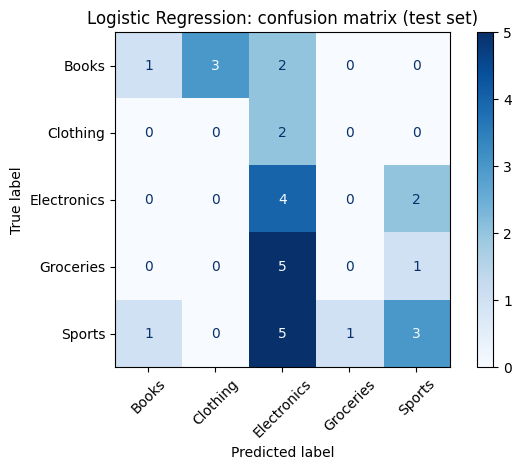

In [29]:
pred = logreg_pipeline.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45, cmap="Blues")
plt.title("Logistic Regression: confusion matrix (test set)")
plt.tight_layout()
plt.show()

## Cross-validation by customer

With roughly 117 rows, one 25% test split is only about 30 rows, so its score is noisy. We repeat the evaluation over 5 customer-grouped folds (stratified so each fold keeps a similar class mix) and look at the mean and spread.

In [30]:
cv = StratifiedGroupKFold(
    n_splits=CONFIG["cv"]["n_splits"],
    shuffle=CONFIG["cv"]["shuffle"],
    random_state=CONFIG["cv"]["random_state"],
)

cv_scores = cross_validate(
    logreg_pipeline, X, y, groups=groups, cv=cv,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro", "log_loss": "neg_log_loss"},
)

cv_table = pd.DataFrame({
    "accuracy": cv_scores["test_accuracy"],
    "f1_macro": cv_scores["test_f1_macro"],
    "log_loss": -cv_scores["test_log_loss"],
})
display(cv_table.round(3))
print("Mean +/- std across folds:")
print(cv_table.agg(["mean", "std"]).round(3).to_string())

,accuracy,f1_macro,log_loss
0,0.111,0.089,2.037
1,0.240,0.230,1.695
2,0.130,0.087,1.799
3,0.296,0.222,1.640
4,0.250,0.191,1.985


Mean +/- std across folds:
      accuracy  f1_macro  log_loss
mean     0.206     0.164     1.831
std      0.081     0.071     0.175


Across the 5 customer-grouped folds, Logistic Regression averages 0.206 accuracy (std 0.081) and 0.164 macro F1, which is no better than the 0.20 you’d get by guessing. The folds swing from 0.111 to 0.296, so on this little data the spread is as large as any gain. The mean log loss is 1.831, worse than the 1.609 you get from guessing all five classes with equal probability, so the model’s probabilities are overconfident. The six social features give a linear model almost nothing to work with, so this is our baseline.

In [31]:
RF_CONFIG = {
    "n_estimators": 300,
    "criterion": "gini",
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "bootstrap": True,
    "class_weight": None,
    "n_jobs": -1,
    "random_state": 42,
}

def make_rf(config):
    return RandomForestClassifier(
        n_estimators=config["n_estimators"],
        criterion=config["criterion"],
        max_depth=config["max_depth"],
        min_samples_split=config["min_samples_split"],
        min_samples_leaf=config["min_samples_leaf"],
        max_features=config["max_features"],
        bootstrap=config["bootstrap"],
        class_weight=config["class_weight"],
        n_jobs=config["n_jobs"],
        random_state=config["random_state"],
    )

RF_CONFIG

{'n_estimators': 300,
 'criterion': 'gini',
 'max_depth': None,
 'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_features': 'sqrt',
 'bootstrap': True,
 'class_weight': None,
 'n_jobs': -1,
 'random_state': 42}

In [32]:
from sklearn.ensemble import RandomForestClassifier

rf = make_rf(RF_CONFIG)
rf_result = evaluate(rf, "Random Forest (base)")

results = pd.DataFrame([baseline_result, logreg_result, rf_result]).set_index("model").round(3)
display(results)

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("\nFeature importances:")
print(importances.round(3).to_string())

,accuracy,f1_macro,log_loss
model,,,
Dummy (class prior),0.200,0.067,1.638
Logistic Regression (base),0.267,0.192,1.902
Random Forest (base),0.233,0.180,2.011



Feature importances:
purchase_interest_score    0.348
engagement_score           0.325
n_positive                 0.099
n_negative                 0.083
n_neutral                  0.075
n_platforms                0.071


In [33]:
rf_cv_scores = cross_validate(
    make_rf(RF_CONFIG), X, y, groups=groups, cv=cv,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro", "log_loss": "neg_log_loss"},
)

rf_cv_table = pd.DataFrame({
    "accuracy": rf_cv_scores["test_accuracy"],
    "f1_macro": rf_cv_scores["test_f1_macro"],
    "log_loss": -rf_cv_scores["test_log_loss"],
})
display(rf_cv_table.round(3))
print("Mean +/- std across folds (Random Forest):")
print(rf_cv_table.agg(["mean", "std"]).round(3).to_string())

,accuracy,f1_macro,log_loss
0,0.111,0.088,2.013
1,0.160,0.121,1.937
2,0.261,0.162,1.932
3,0.296,0.206,1.685
4,0.167,0.112,2.182


Mean +/- std across folds (Random Forest):
      accuracy  f1_macro  log_loss
mean     0.199     0.138      1.95
std      0.077     0.046      0.18


Random Forest did not beat Logistic Regression. On the test split it scores 0.233 accuracy and 0.180 macro F1 against 0.267 and 0.192, and in cross-validation it averages 0.199 accuracy (std 0.077) and 0.138 macro F1 against 0.206 and 0.164. Its log loss is the worst of the three, 2.011 on the split and 1.950 in cross-validation, against the dummy’s 1.638, so it is overconfident. This is the overfitting I expected, since fully grown trees on about 90 training rows memorise noise. The top features are purchase_interest_score (0.348) and engagement_score (0.325), but that mostly reflects the forest finding it easier to split on continuous values than on the small counts, so don’t read it as evidence that those two features predict the product.

In [34]:
RF_EXPERIMENTS = {
    "rf_depth3_leaf5": {
        "n_estimators": 300,
        "criterion": "gini",
        "max_depth": 3,
        "min_samples_split": 2,
        "min_samples_leaf": 5,
        "max_features": "sqrt",
        "bootstrap": True,
        "class_weight": None,
        "n_jobs": -1,
        "random_state": 42,
    },
    "rf_depth3_leaf10": {
        "n_estimators": 300,
        "criterion": "gini",
        "max_depth": 3,
        "min_samples_split": 2,
        "min_samples_leaf": 10,
        "max_features": "sqrt",
        "bootstrap": True,
        "class_weight": None,
        "n_jobs": -1,
        "random_state": 42,
    },
    "rf_depth5_leaf10": {
        "n_estimators": 300,
        "criterion": "gini",
        "max_depth": 5,
        "min_samples_split": 2,
        "min_samples_leaf": 10,
        "max_features": "sqrt",
        "bootstrap": True,
        "class_weight": None,
        "n_jobs": -1,
        "random_state": 42,
    },
    "rf_depth3_leaf10_half_features": {
        "n_estimators": 300,
        "criterion": "gini",
        "max_depth": 3,
        "min_samples_split": 2,
        "min_samples_leaf": 10,
        "max_features": 0.5,
        "bootstrap": True,
        "class_weight": None,
        "n_jobs": -1,
        "random_state": 42,
    },
}

CV_SEEDS = [42, 43, 44]

In [35]:
def repeated_cv(model_factory, seeds=CV_SEEDS):
    rows = []
    for seed in seeds:
        fold_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        scores = cross_validate(
            model_factory(), X, y, groups=groups, cv=fold_cv,
            scoring={"accuracy": "accuracy", "f1_macro": "f1_macro", "log_loss": "neg_log_loss"},
        )
        rows.append(pd.DataFrame({
            "accuracy": scores["test_accuracy"],
            "f1_macro": scores["test_f1_macro"],
            "log_loss": -scores["test_log_loss"],
        }))
    return pd.concat(rows, ignore_index=True)

models = {
    "dummy_prior": lambda: DummyClassifier(strategy=CONFIG["dummy"]["strategy"]),
    "logreg_base": lambda: logreg_pipeline,
    "rf_base": lambda: make_rf(RF_CONFIG),
}
for name, cfg in RF_EXPERIMENTS.items():
    models[name] = (lambda c=cfg: make_rf(c))

summary = {}
for name, factory in models.items():
    scores = repeated_cv(factory)
    summary[name] = scores.agg(["mean", "std"]).T.stack()

summary_table = pd.DataFrame(summary).T
summary_table.columns = [f"{m}_{s}" for m, s in summary_table.columns]
display(summary_table.round(3).sort_values("log_loss_mean"))

,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,log_loss_mean,log_loss_std
dummy_prior,0.180,0.056,0.060,0.017,1.635,0.036
rf_depth3_leaf10,0.222,0.085,0.147,0.064,1.664,0.050
rf_depth5_leaf10,0.220,0.082,0.145,0.062,1.665,0.051
rf_depth3_leaf10_half_features,0.212,0.094,0.140,0.072,1.673,0.059
rf_depth3_leaf5,0.218,0.089,0.151,0.070,1.697,0.070
logreg_base,0.225,0.078,0.172,0.071,1.797,0.130
rf_base,0.214,0.063,0.147,0.060,1.939,0.177


Every model is inside the noise of the others. Accuracy sits between 0.212 and 0.225 for all six, with a standard deviation of about 0.08, so differences of 0.01 are meaningless. The dummy is at 0.180, and the gap to the models is also smaller than that spread. Log loss tells the clearer story. Constraining the forest worked as hoped: rf_depth3_leaf10 brings log loss down from 1.939 (base RF) to 1.664, which is essentially the dummy’s 1.635 (std 0.05). So the constrained forest has stopped being overconfident, but it hasn’t found real signal. logreg_base is worse on log loss (1.797), and the more flexible forests (depth3_leaf5, base) are worse again.

The model's performance is relatively low and that is due to limited dataset of just 61 unique customers, and the varies in features values makes it very difficult to distinguish customers and learn a reasonable pattern.

In [37]:
import joblib

FINAL_NAME = "rf_depth3_leaf10"
final_model = make_rf(RF_EXPERIMENTS[FINAL_NAME])
final_model.fit(X, y)

artifact = {
    "model": final_model,
    "feature_cols": feature_cols,
    "classes": list(final_model.classes_),
    "config": RF_EXPERIMENTS[FINAL_NAME],
}
joblib.dump(artifact, "product_model.joblib")

# sanity check: reload and predict one row
loaded = joblib.load("product_model.joblib")
sample = X.iloc[[0]][loaded["feature_cols"]]
proba = loaded["model"].predict_proba(sample)[0]
print(dict(zip(loaded["classes"], proba.round(3))))

files.download("product_model.joblib")

{'Books': np.float64(0.193), 'Clothing': np.float64(0.128), 'Electronics': np.float64(0.097), 'Groceries': np.float64(0.234), 'Sports': np.float64(0.348)}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>